In [43]:
import pandas
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

In [44]:
df = pd.read_csv('/content/drive/MyDrive/students.csv')
df.head()

,StudentID,StudyHours,SleepHours,DoneHomework,Attendance,Passed
0,1,1,5,No,Poor,No
1,2,2,6,No,Poor,No
2,3,2,7,Yes,Good,No
3,4,3,6,Yes,Poor,No
4,5,3,8,Yes,Good,Yes


In [45]:
CSV_PATH = "students.csv"
TARGET = "Passed"
DROP_COLS = ["StudentID"]
CRITERION = "entropy"
MAX_DEPTH = 3

In [46]:
df.shape

(20, 6)

In [47]:
X = df.drop(columns=[TARGET] + DROP_COLS)
y = df[TARGET]
print("Number of features:", X.shape[1])
print("Features:", list(X.columns), "\n")

Number of features: 4
Features: ['StudyHours', 'SleepHours', 'DoneHomework', 'Attendance'] 



In [48]:
x=pd.get_dummies

In [49]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [50]:
X_encoded = pd.get_dummies(X, drop_first=True)
x_train, x_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier(criterion=CRITERION, max_depth=MAX_DEPTH, random_state=42)
model.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

In [51]:
train_predictions = model.predict(x_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("Training Accuracy:", train_accuracy)

Training Accuracy: 0.9375


In [52]:
test_predictions = model.predict(x_test)
test_accuracy = accuracy_score(y_test, test_predictions)
print("Testing Accuracy:", test_accuracy)

Testing Accuracy: 0.75


In [53]:
print(confusion_matrix(y_test, test_predictions))

[[2 1]
 [0 1]]


In [54]:
print(export_text(model, feature_names=list(X.columns)))

|--- SleepHours <= 5.50
|   |--- class: No
|--- SleepHours >  5.50
|   |--- StudyHours <= 4.50
|   |   |--- Attendance <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Attendance >  0.50
|   |   |   |--- class: No
|   |--- StudyHours >  4.50
|   |   |--- class: Yes



In [55]:
importances = pd.Series(model.feature_importances_, index=X.columns)
print("Feature importance:\n", importances.sort_values(ascending=False).head(10), "\n")

Feature importance:
 StudyHours      0.421602
SleepHours      0.410624
Attendance      0.167774
DoneHomework    0.000000
dtype: float64 



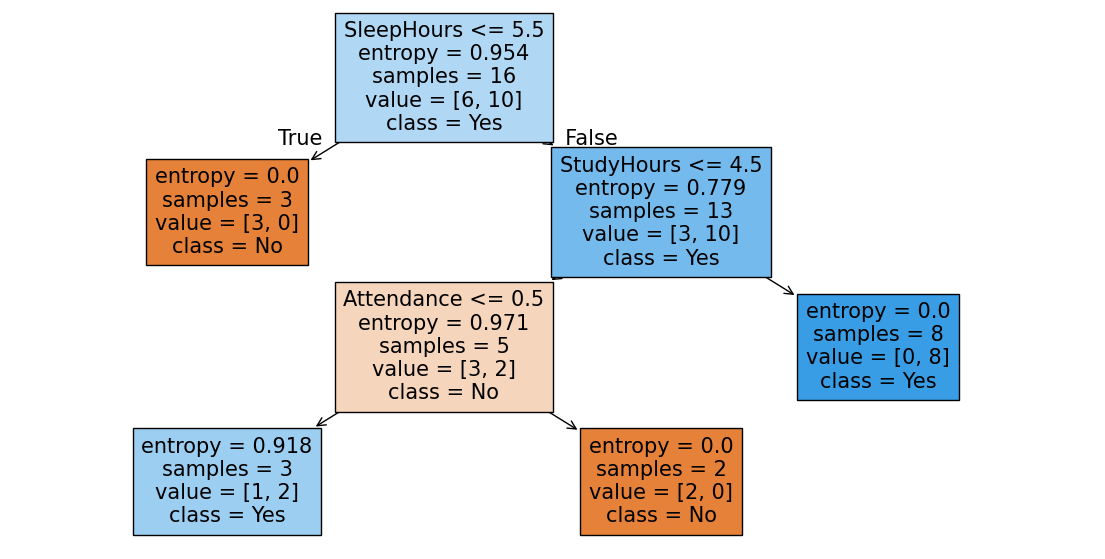

In [56]:
# 9. Draw the tree
plt.figure(figsize=(14, 7))
plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=[str(c) for c in model.classes_],
    filled=True,
)
plt.show()


In [57]:
# 10. Overfitting experiment: compare different depths
print("Depth | Train acc | Test acc")
for depth in [1, 2, 3, 5, 10, None]:
    m = DecisionTreeClassifier(criterion=CRITERION, max_depth=depth, random_state=42)
    m.fit(x_train, y_train)
    print(f"{str(depth):>5} |   {m.score(x_train, y_train):.2f}    |  {m.score(x_test, y_test):.2f}")

Depth | Train acc | Test acc
    1 |   0.81    |  0.50
    2 |   0.88    |  0.75
    3 |   0.94    |  0.75
    5 |   1.00    |  1.00
   10 |   1.00    |  1.00
 None |   1.00    |  1.00
